In [183]:
import numpy as np
import pandas as pd
from joblib import load
from utils.paths import DATASETS_PREPROCESSED_DIR, PROJECT_ROOT
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_absolute_percentage_error

pp_models_dir = PROJECT_ROOT / "power_prediction" / "models"
ar_models_dir = PROJECT_ROOT / "autoregression-models" / "models"

alpha = 0.05

In [184]:
TARGET_LAGS = [1, 2, 3, 4, 5, 6, 24, 48]
FEATURE_LAGS = {
    "temperature_2m": [1, 17],
    "relative_humidity_2m": [6, 30],
    "wind_speed_10m": [6, 30],
    "wind_gusts_10m": [6, 30],
}


def add_lags(df, horizon):
    lagged = df.copy()
    lagged["hour"] = pd.to_datetime(lagged["time"]).dt.hour
    lagged["dayofweek"] = pd.to_datetime(lagged["time"]).dt.dayofweek
    lagged["month"] = pd.to_datetime(lagged["time"]).dt.month
    lagged["row_idx"] = np.arange(len(lagged))

    for lag in TARGET_LAGS:
        lagged[f"delta_p_lag_{lag}"] = lagged["delta_p"].shift(lag)

    for feature, lags in FEATURE_LAGS.items():
        for lag in lags:
            lagged[f"{feature}_lag_{lag}"] = lagged[feature].shift(lag)

    lagged["target"] = lagged["delta_p"].shift(-horizon)
    lagged = lagged.dropna().reset_index(drop=True)

    return lagged

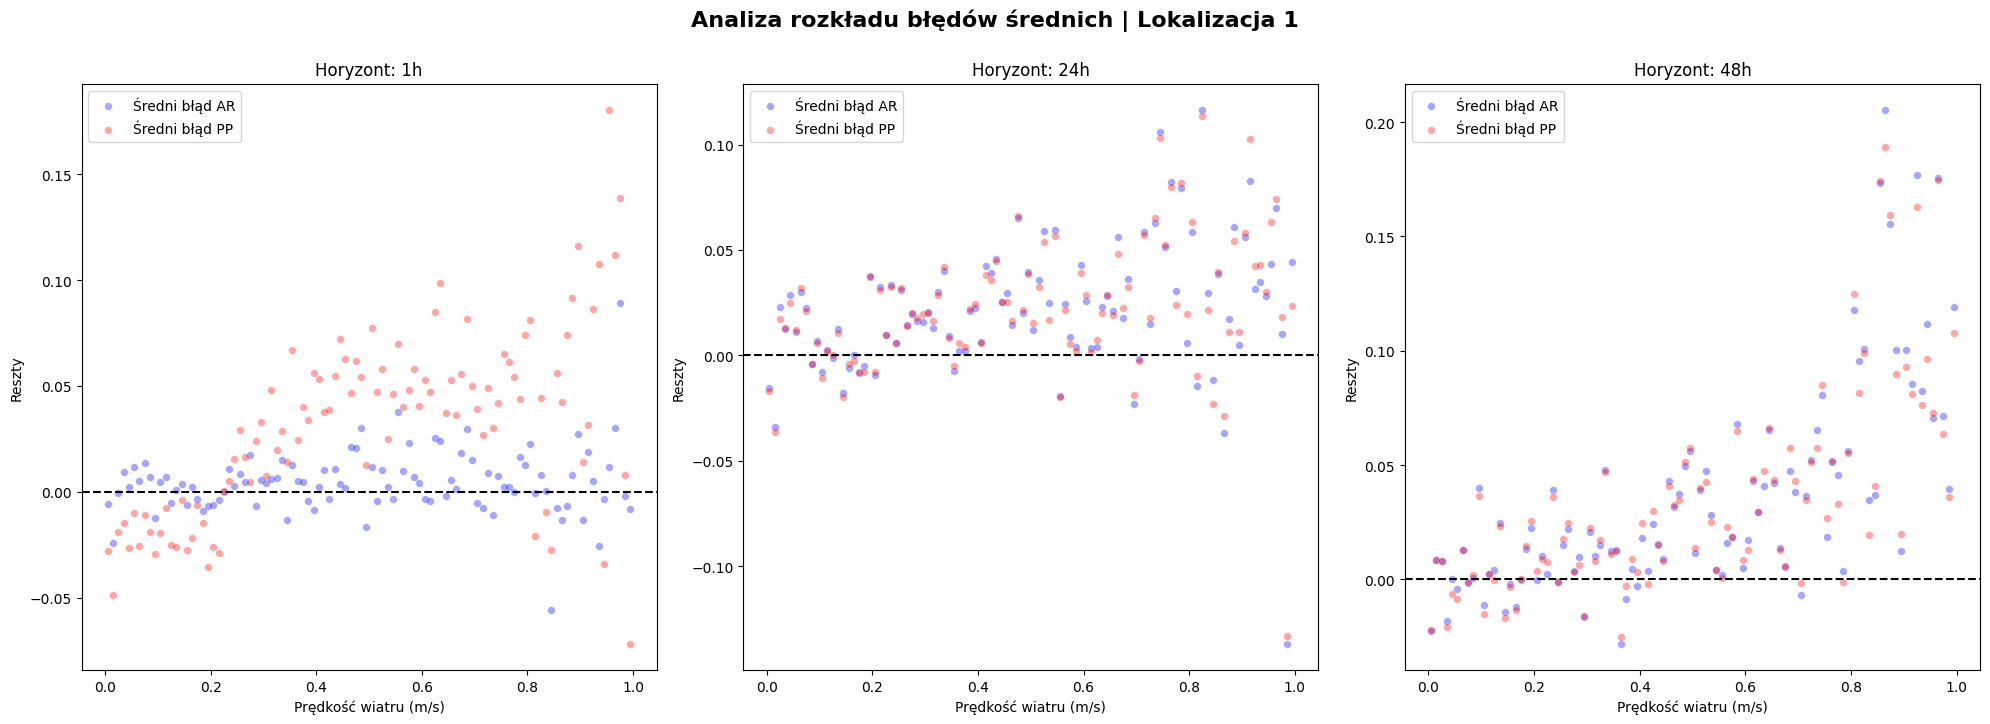

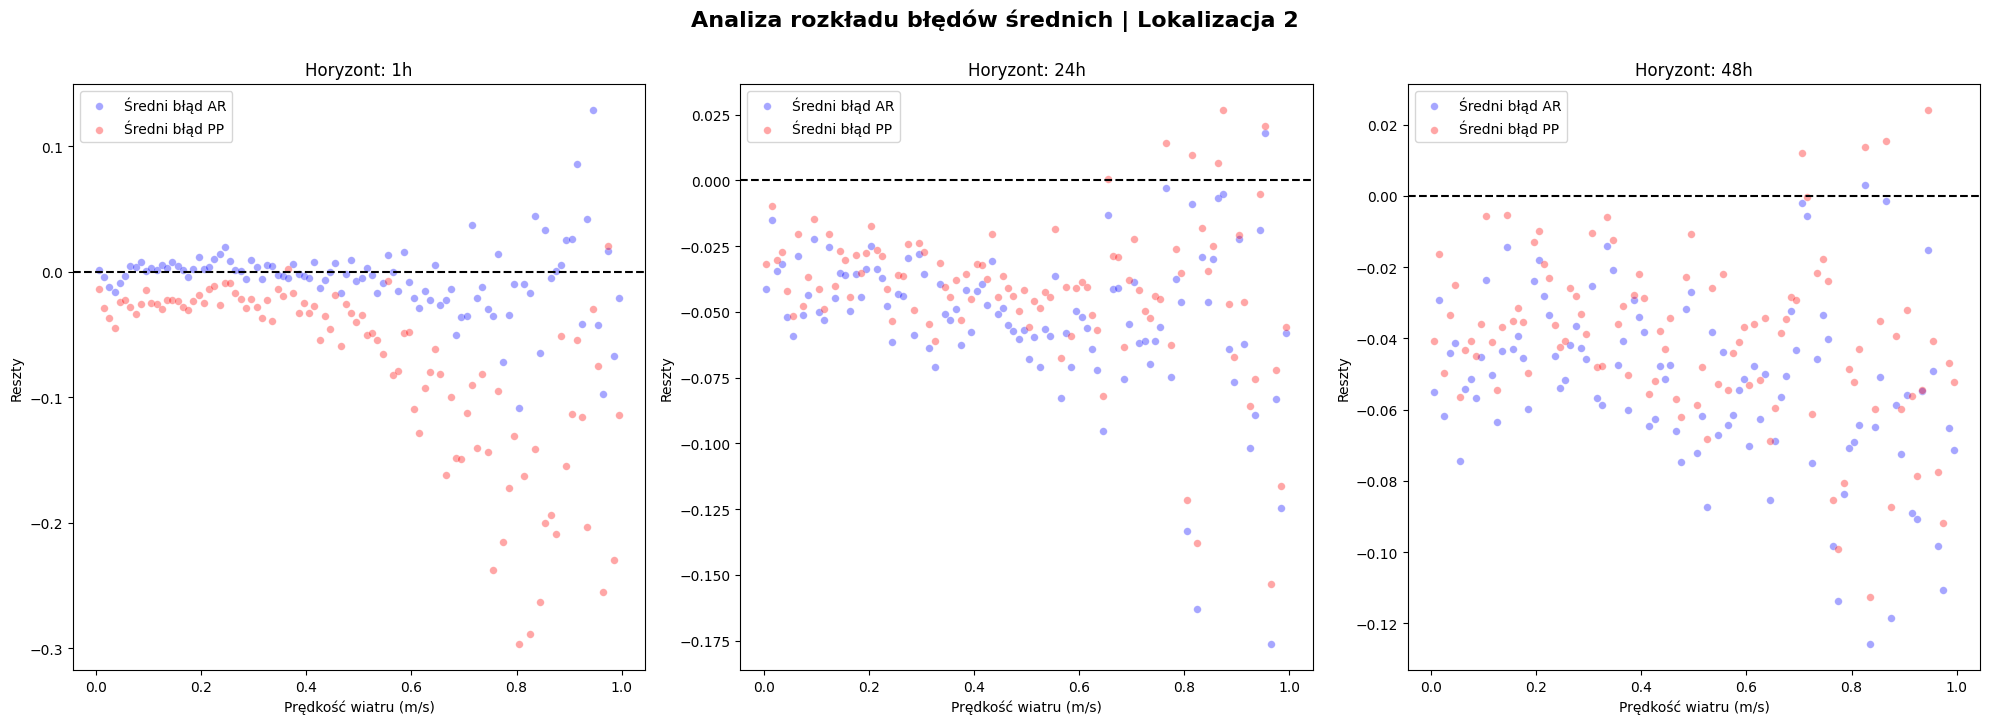

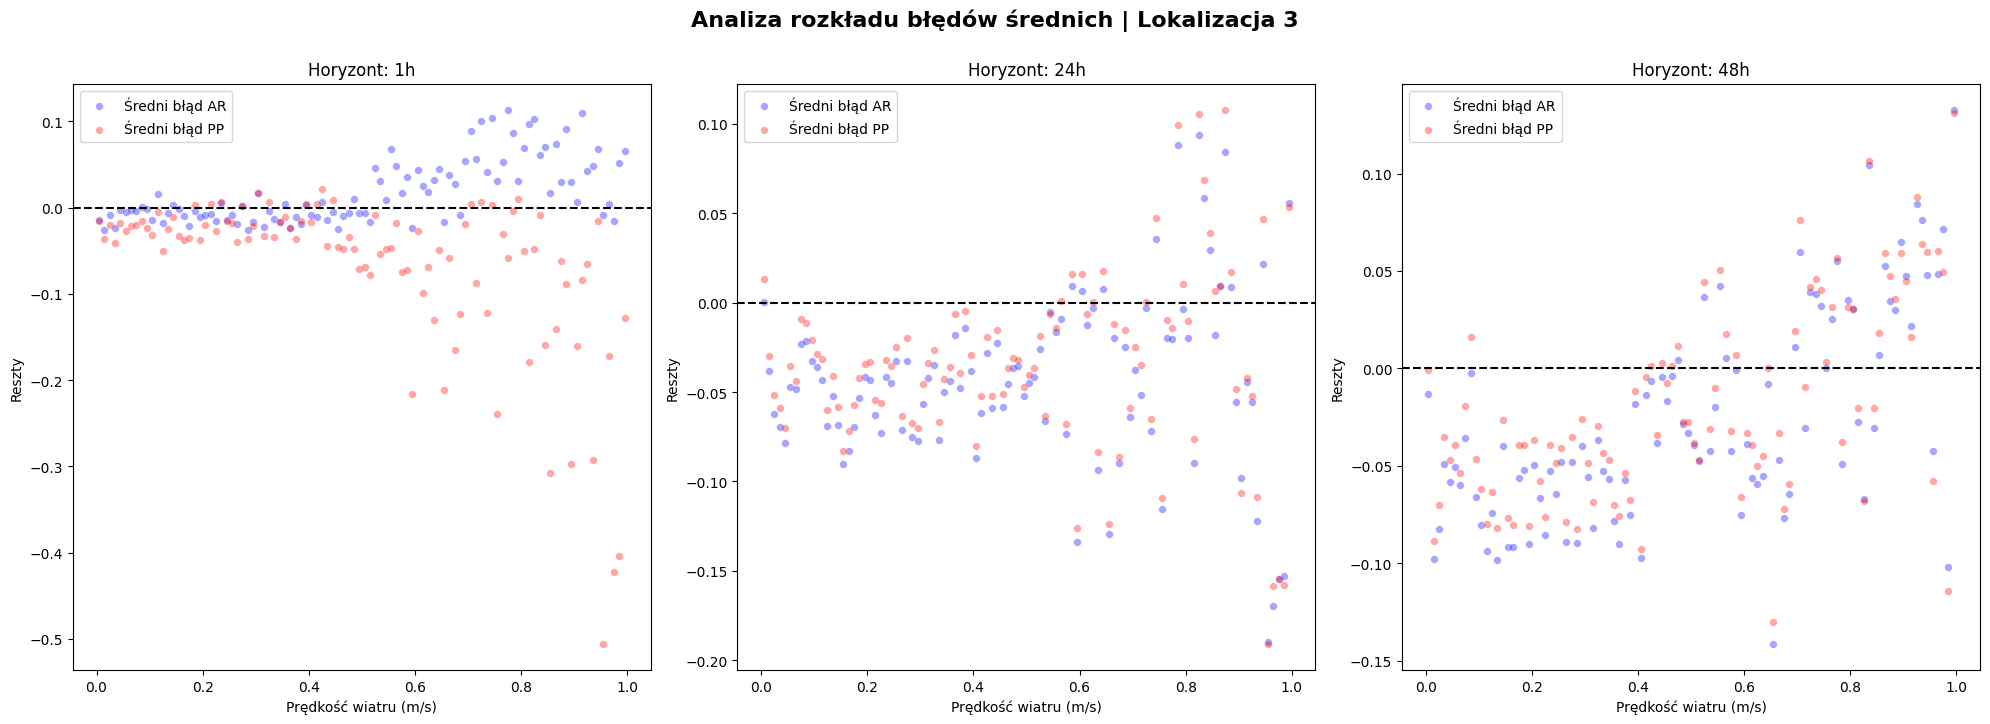

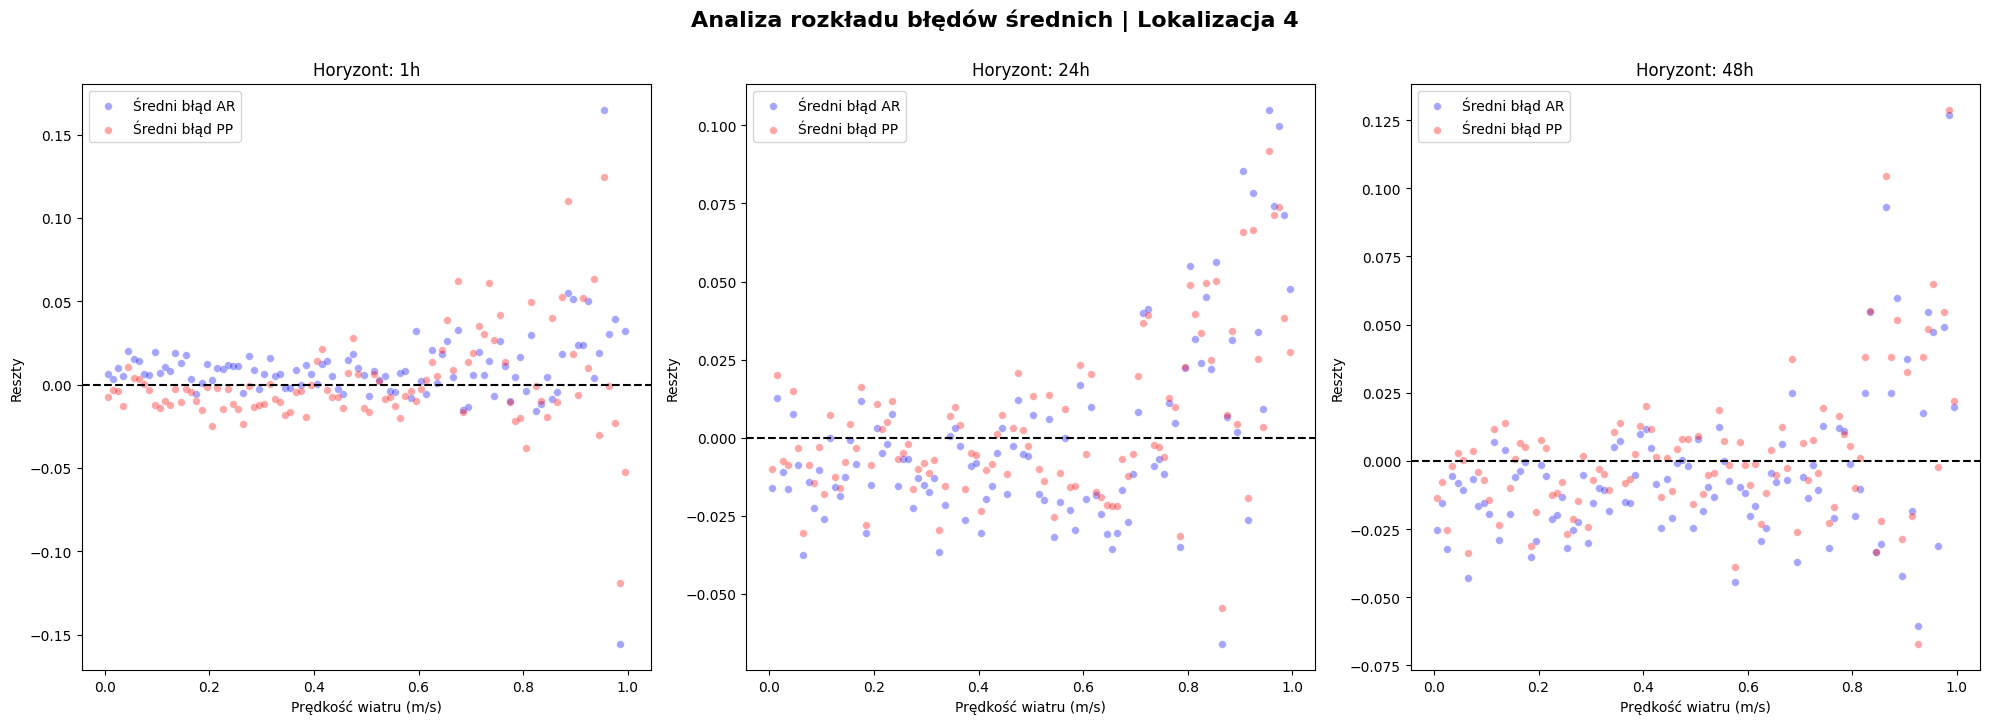

In [185]:
horizon_to_col = {1: 0, 24: 1, 48: 2}
wind_analysis = pd.DataFrame()
rmse_df = pd.DataFrame()
mae_df = pd.DataFrame()
r2_df = pd.DataFrame()
mape_df = pd.DataFrame()

for loc in range(1, 5):
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 8))
    fig.suptitle(f"Analiza rozkładu błędów średnich | Lokalizacja {loc}", fontsize=16, fontweight='bold', y=0.9)
    df = pd.read_csv(DATASETS_PREPROCESSED_DIR / f"Location_{loc}_test.csv")

    X_pp = df.drop(columns=["time", "p_base", "delta_p"])
    y_pp_all = load(pp_models_dir / f"stacking_model_loc{loc}.pkl").predict(X_pp)

    for horizon in [1, 24, 48]:
        lagged = add_lags(df, horizon)
        # ar_model = load(ar_models_dir / f"stacking_regressor_h{horizon}.pkl")
        ar_model = load(ar_models_dir / f"hybrid_h{horizon}_s10.pkl")

        X_ar = lagged.drop(columns=["time", "delta_p", "target", "p_base", "row_idx"])
        y = lagged["target"].to_numpy()
        y_ar = ar_model.predict(X_ar)
        y_pp = np.asarray(y_pp_all)[lagged["row_idx"].to_numpy() + horizon]  # getting only the predictions corresponding to the lagged rows

        res_ar = y - y_ar
        res_pp = y - y_pp

        rmse_ar = np.sqrt(np.mean(res_ar**2))
        rmse_pp = np.sqrt(np.mean(res_pp**2))
        mae_ar = np.mean(np.abs(res_ar))
        mae_pp = np.mean(np.abs(res_pp))
        r2_ar = r2_score(y, y_ar)
        r2_pp = r2_score(y, y_pp)
        mape_ar = mean_absolute_percentage_error(y, y_ar)
        mape_pp = mean_absolute_percentage_error(y, y_pp)

        lagged["wind_bins"] = pd.cut(lagged["wind_speed_100m"], bins=np.arange(0, 1.01, 0.01))  # 1.01 needed to include 1.0 in the last bin
        lagged["residuals_ar"] = res_ar
        lagged["residuals_pp"] = res_pp
        lagged["rmse_ar"] = rmse_ar
        lagged["rmse_pp"] = rmse_pp
        lagged["mae_ar"] = mae_ar
        lagged["mae_pp"] = mae_pp
        lagged["r2_ar"] = r2_ar
        lagged["r2_pp"] = r2_pp
        lagged["mape_ar"] = mape_ar
        lagged["mape_pp"] = mape_pp

        current_errors = lagged.groupby("wind_bins").agg(
            mean_error_ar=("residuals_ar", "mean"),
            mae_ar=("residuals_ar", lambda x: np.mean(np.abs(x))),
            rmse_ar=("residuals_ar", lambda x: np.sqrt(np.mean(x**2))),
            mean_error_pp=("residuals_pp", "mean"),
            mae_pp=("residuals_pp", lambda x: np.mean(np.abs(x))),
            rmse_pp=("residuals_pp", lambda x: np.sqrt(np.mean(x**2))),
            count=("residuals_ar", "count")
        ).reset_index()

        # compute bin midpoints on aggregated frame
        current_errors["wind_bins_mid"] = current_errors["wind_bins"].apply(lambda x: x.mid)

        current_errors["location"] = loc
        current_errors["horizon"] = horizon
        wind_analysis = pd.concat([wind_analysis, current_errors], ignore_index=True)

        rmse_df = pd.concat([rmse_df, pd.DataFrame({
            "location": [loc], 
            "horizon": [horizon],
            "rmse_ar": [rmse_ar], 
            "rmse_pp": [rmse_pp]
        })], ignore_index=True)

        mae_df = pd.concat([mae_df, pd.DataFrame({
            "location": [loc], 
            "horizon": [horizon],
            "mae_ar": [mae_ar],
            "mae_pp": [mae_pp]
        })], ignore_index=True)

        r2_df = pd.concat([r2_df, pd.DataFrame({
            "location": [loc],
            "horizon": [horizon],
            "r2_ar": [r2_ar],
            "r2_pp": [r2_pp]
        })], ignore_index=True)

        mape_df = pd.concat([mape_df, pd.DataFrame({
            "location": [loc],
            "horizon": [horizon],
            "mape_ar": [mape_ar],
            "mape_pp": [mape_pp]
        })], ignore_index=True)

        # row_idx = loc - 1
        col_idx = horizon_to_col[horizon]
        ax = axes[horizon_to_col[horizon]]

        sns.scatterplot(x=current_errors["wind_bins_mid"], y=current_errors["mean_error_ar"], alpha=0.35, ax=ax, s=30, color='blue', label='Średni błąd AR', zorder=2)
        sns.scatterplot(x=current_errors["wind_bins_mid"], y=current_errors["mean_error_pp"], alpha=0.35, ax=ax, s=30, color='red', label='Średni błąd PP', zorder=2)
        ax.axhline(y=0, color="black", linestyle="--")

        ax.set_title(f"Horyzont: {horizon}h")
        ax.set_ylabel("Reszty")
        ax.set_xlabel("Prędkość wiatru (m/s)")

    plt.tight_layout(rect=[0, 0, 1, 0.90])
    plt.show()


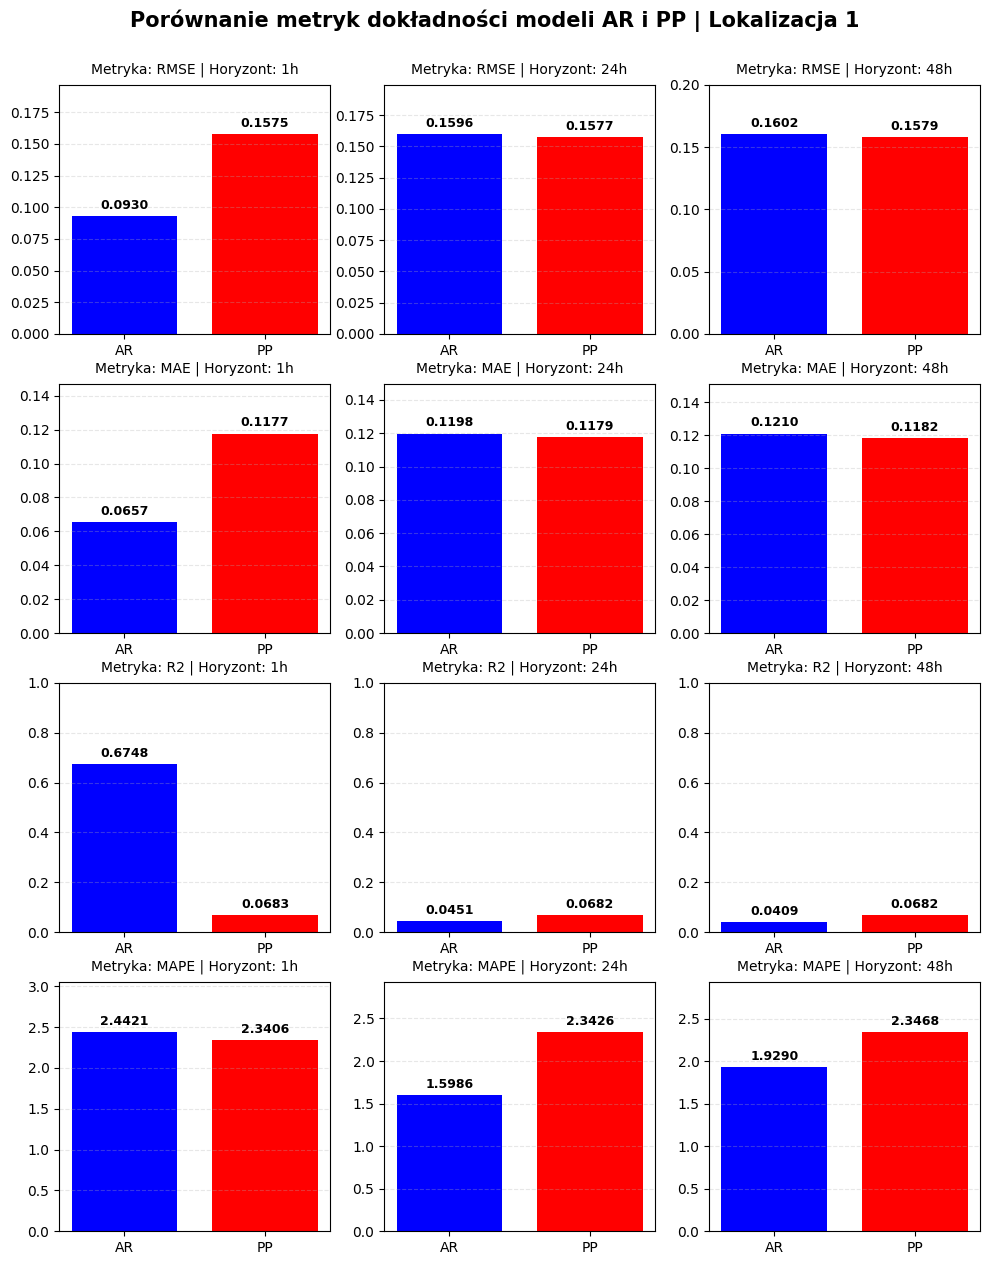

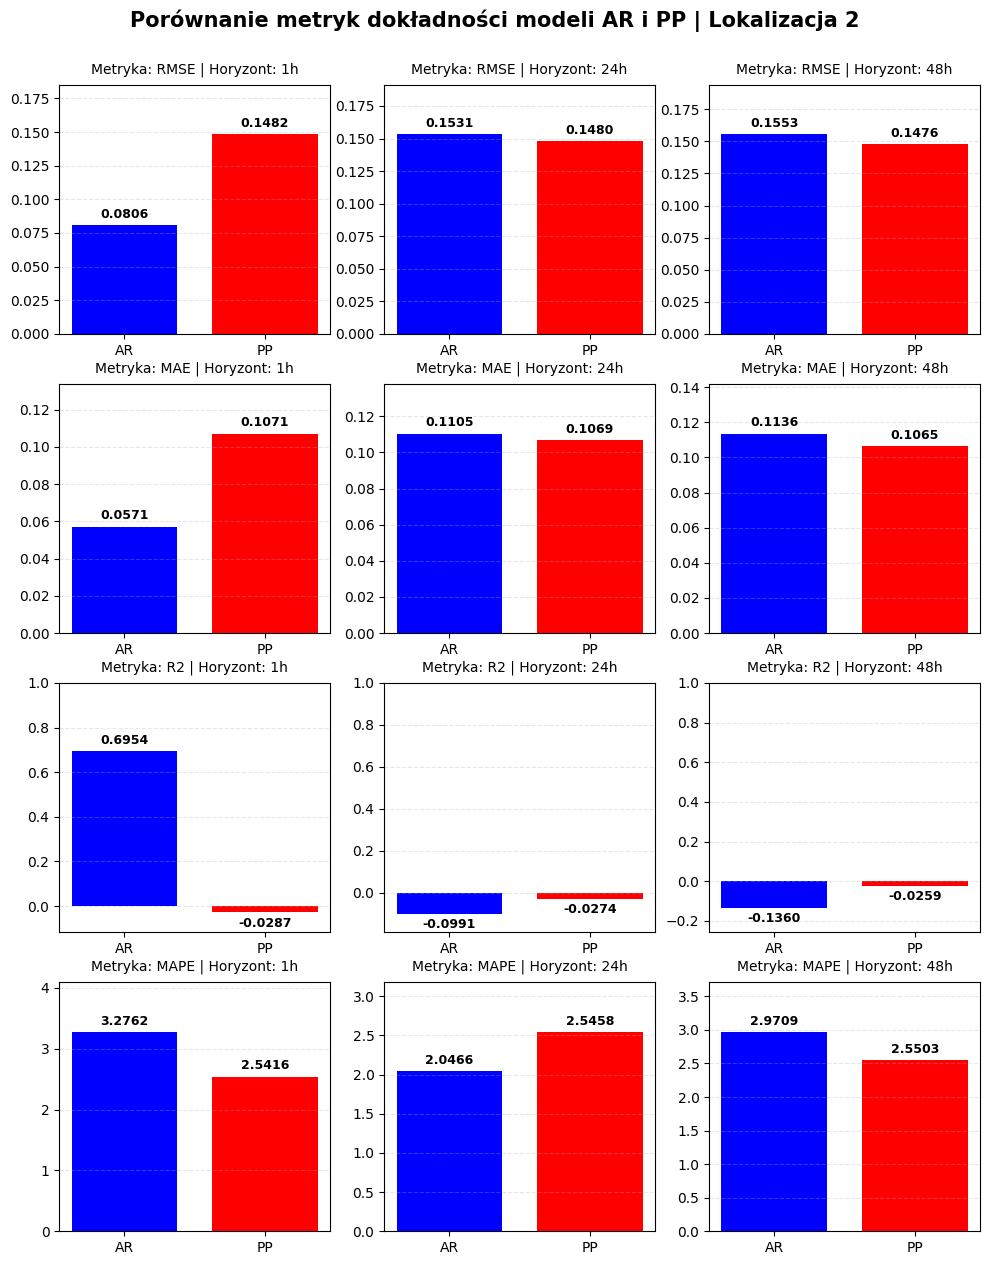

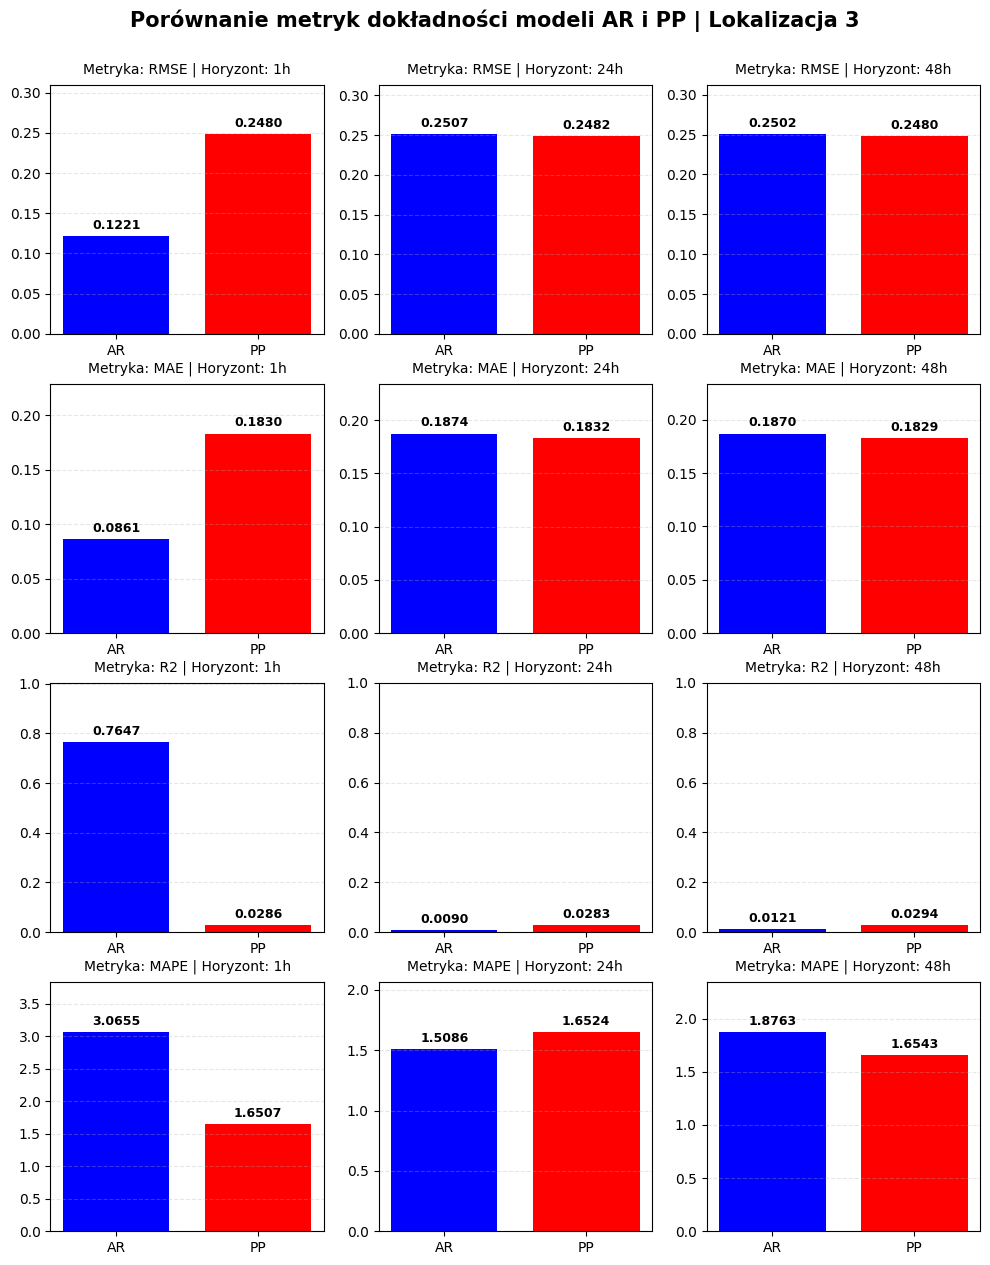

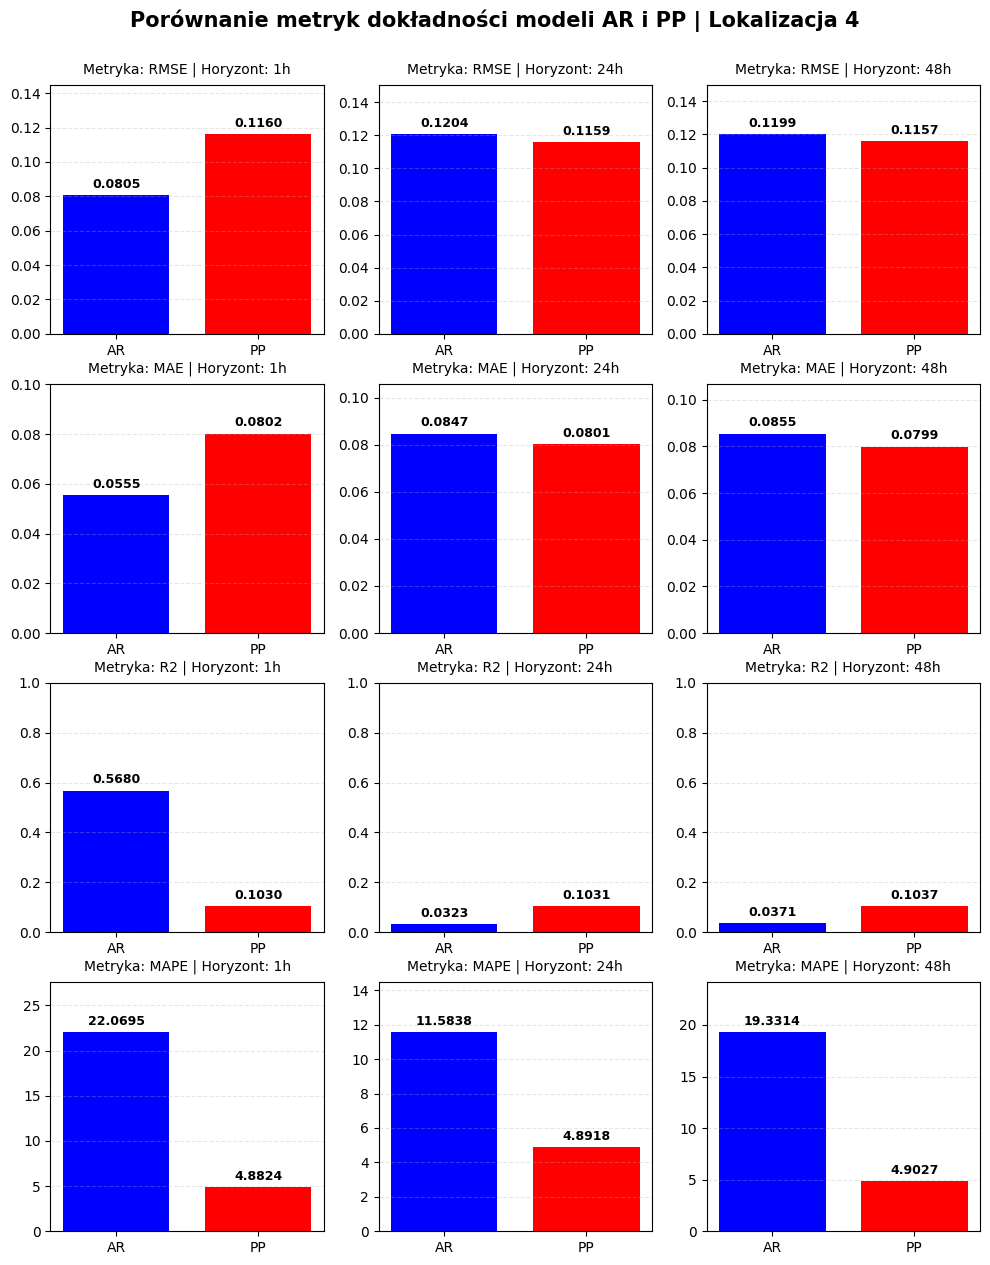

In [186]:
metrics = ["RMSE", "MAE", "R2", "MAPE"]
metrics_values = [rmse_df, mae_df, r2_df, mape_df]

for loc in range(1, 5):
    fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(10, 14))

    for horizon in [1, 24, 48]:
        for i, metric in enumerate(metrics):
            row_idx = i
            col_idx = horizon_to_col[horizon]
            ax = axes[row_idx, col_idx]

            row = metrics_values[i][(metrics_values[i].location == loc) & (metrics_values[i].horizon == horizon)].iloc[0]
            val_ar = row[f"{metric.lower()}_ar"]
            val_pp = row[f"{metric.lower()}_pp"]
            
            bars = ax.bar(["AR", "PP"], [val_ar, val_pp], color=['blue', 'red'], width=0.75)
            
            ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=9, weight='bold')
            
            y_min, y_max = ax.get_ylim()
            if metric == "R2": ax.set_ylim(bottom=min(0, y_min * 1.8), top=max(1.0, y_max * 1.25))
            else: ax.set_ylim(bottom=0, top=max(val_ar, val_pp) * 1.25)

            ax.set_title(f"Metryka: {metric} | Horyzont: {horizon}h", fontsize=10, pad=8)
            ax.grid(axis='y', linestyle='--', alpha=0.3)

    fig.suptitle(f"Porównanie metryk dokładności modeli AR i PP | Lokalizacja {loc}", fontsize=15, y=0.90, weight='bold')
    
    plt.tight_layout(rect=[0, 0, 1, 0.90])
    plt.subplots_adjust(hspace=0.2, wspace=0.2)
    plt.show()

In [187]:
pd.set_option('display.max_rows', None) # it should disply all df lines only in this notebook, if it does it globally remove this line
wind_analysis

,wind_bins,mean_error_ar,mae_ar,rmse_ar,mean_error_pp,mae_pp,rmse_pp,count,wind_bins_mid,location,horizon
0,"(0.0, 0.01]",-0.005747,0.058627,0.091769,-2.773824e-02,0.067905,0.112914,83,0.005,1,1
1,"(0.01, 0.02]",-0.024100,0.059681,0.082297,-4.846644e-02,0.060381,0.089695,65,0.015,1,1
2,"(0.02, 0.03]",-0.000618,0.056101,0.075465,-1.888634e-02,0.062003,0.085454,84,0.025,1,1
3,"(0.03, 0.04]",0.009549,0.070965,0.089742,-1.481753e-02,0.082173,0.116192,88,0.035,1,1
4,"(0.04, 0.05]",0.002534,0.059378,0.081237,-2.624752e-02,0.073069,0.098587,91,0.045,1,1
5,"(0.05, 0.06]",0.011810,0.066780,0.122201,-1.014476e-02,0.098092,0.158395,98,0.055,1,1
6,"(0.06, 0.07]",0.005292,0.059433,0.081093,-2.525075e-02,0.075682,0.105191,97,0.065,1,1
7,"(0.07, 0.08]",0.013466,0.062399,0.086748,-1.077719e-02,0.085616,0.116559,122,0.075,1,1
8,"(0.08, 0.09]",0.007061,0.061303,0.080336,-1.879051e-02,0.090017,0.113635,135,0.085,1,1
9,"(0.09, 0.1]",-0.012198,0.057459,0.086817,-2.941704e-02,0.092380,0.128140,129,0.095,1,1
